# Analyzing NFL Data

Markdown cells were typed by Benjamin Robinson and enhanced by Codex.

**Data limitation:** Weekly Next Gen Stats receiving data covers only a subset of receivers and targets. In the 2024 regular-season data checked, all included receivers were wide receivers or tight ends with at least five targets that week. The target-weighted separation average therefore represents the included receivers, and coverage varies between teams and games. This may bias comparisons of quarterback EPA per dropback. Results should be interpreted as associations within the available data, and cannot establish that greater separation causes improved quarterback performance.

In [108]:
import nflreadpy as nfl

receiving = nfl.load_nextgen_stats(
    seasons=2024,
    stat_type="receiving",
).to_pandas()

receiving.head()

,season,season_type,week,player_display_name,player_position,team_abbr,avg_cushion,avg_separation,avg_intended_air_yards,percent_share_of_intended_air_yards,...,yards,rec_touchdowns,avg_yac,avg_expected_yac,avg_yac_above_expectation,player_gsis_id,player_first_name,player_last_name,player_jersey_number,player_short_name
0,2024,REG,0,Ray-Ray McCloud,WR,ATL,8.143947,3.187889,6.720460,13.054215,...,686.0,1,5.636613,4.465059,1.171554,00-0034407,Ray-Ray,McCloud,34,R.McCloud
1,2024,REG,0,Marvin Mims,WR,DEN,7.996364,5.205588,7.139808,9.146722,...,501.0,6,12.414103,9.636653,2.777450,00-0038976,Marvin,Mims,19,M.Mims
2,2024,REG,0,Tutu Atwell,WR,LAR,7.494035,3.368998,11.851452,18.011678,...,562.0,0,2.897143,3.496919,-0.599777,00-0036849,Chatarius,Atwell,5,T.Atwell
3,2024,REG,0,Greg Dortch,WR,ARI,7.475250,3.688801,4.251600,5.757699,...,342.0,3,8.034324,5.521061,2.513264,00-0035500,Greg,Dortch,4,G.Dortch
4,2024,REG,0,Troy Franklin,WR,DEN,7.358235,3.805753,13.236604,17.283354,...,263.0,2,6.086786,5.645541,0.441245,00-0039868,Troy,Franklin,16,T.Franklin


In [109]:
receiving_weekly = receiving.loc[
    (receiving["season_type"] == "REG") & (receiving["week"] > 0)
].copy()

receiving_weekly.head()

,season,season_type,week,player_display_name,player_position,team_abbr,avg_cushion,avg_separation,avg_intended_air_yards,percent_share_of_intended_air_yards,...,yards,rec_touchdowns,avg_yac,avg_expected_yac,avg_yac_above_expectation,player_gsis_id,player_first_name,player_last_name,player_jersey_number,player_short_name
129,2024,REG,1,Colby Parkinson,TE,LAR,10.060000,4.141933,2.320000,3.941556,...,47.0,0,7.440000,6.064563,1.375437,00-0036244,Colby,Parkinson,86,C.Parkinson
130,2024,REG,1,Wan'Dale Robinson,WR,NYG,9.161111,3.628257,4.841667,34.238906,...,44.0,0,1.608333,2.373876,-0.765543,00-0038117,Charles,Robinson,17,W.Robinson
131,2024,REG,1,Tank Dell,WR,HOU,8.961429,2.593567,16.072857,44.842567,...,40.0,0,2.900000,1.760096,1.139904,00-0038977,Nathaniel,Dell,3,T.Dell
132,2024,REG,1,Adonai Mitchell,WR,IND,8.470000,3.159241,17.212000,27.471510,...,2.0,0,2.890000,4.687616,-1.797616,00-0039890,Adonai,Mitchell,10,A.Mitchell
133,2024,REG,1,Michael Pittman,WR,IND,8.152500,1.946336,9.472500,24.189996,...,31.0,0,1.847500,1.318451,0.529049,00-0036252,Michael,Pittman,11,M.Pittman


I am investigating which quarterbacks show the largest increase in EPA per dropback in games where their receivers average more separation. I plan to analyze the 2020–2025 regular seasons, starting with 2024 to explore the data and develop the analysis.

In [110]:
columns = ["season", "week", "team_abbr", "player_gsis_id", "targets", "avg_separation"]

print(receiving_weekly[columns].isna().sum())

print(
    "Duplicate receiver-week records:",
    receiving_weekly.duplicated(
        subset=["season", "week", "team_abbr", "player_gsis_id"],
    ).sum(),
)

season            0
week              0
team_abbr         0
player_gsis_id    0
targets           0
avg_separation    0
dtype: int64
Duplicate receiver-week records: 0


I checked the required columns for missing values and checked for duplicate receiver records within each team, season, and week. Both checks returned zero, so no rows needed to be removed at this step.

In [111]:
receiving_weekly["weighted_separation"] = (
    receiving_weekly["avg_separation"] * receiving_weekly["targets"]
)

team_separation = receiving_weekly.groupby(
    ["season", "week", "team_abbr"],
    as_index=False,
).agg(
    weighted_separation=("weighted_separation", "sum"),
    tracked_targets=("targets", "sum"),
)

team_separation["avg_separation"] = team_separation["weighted_separation"] / team_separation[
    "tracked_targets"
].where(
    team_separation["tracked_targets"] > 0,
)

team_separation.head()

,season,week,team_abbr,weighted_separation,tracked_targets,avg_separation
0,2024,1,ARI,48.540333,17,2.855314
1,2024,1,ATL,21.081861,7,3.011694
2,2024,1,BAL,117.431580,27,4.349318
3,2024,1,BUF,13.315117,5,2.663023
4,2024,1,CAR,44.348591,18,2.463811


I weighted each receiver’s average separation by their number of targets so receivers with more targets contribute more to the team average. I multiplied `avg_separation` by `targets`, summed those products for each team and week, and divided by the total targets.

In [112]:
pbp = nfl.load_pbp(2024).to_pandas()

pbp[
    [
        "season",
        "week",
        "season_type",
        "posteam",
        "passer_player_id",
        "passer_player_name",
        "qb_dropback",
        "qb_scramble",
        "epa",
    ]
].head()

,season,week,season_type,posteam,passer_player_id,passer_player_name,qb_dropback,qb_scramble,epa
0,2024,1,REG,NaN,NaN,NaN,NaN,0.0,-0.000000
1,2024,1,REG,ARI,NaN,NaN,0.0,0.0,0.257819
2,2024,1,REG,ARI,NaN,NaN,0.0,0.0,-0.200602
3,2024,1,REG,ARI,00-0035228,K.Murray,1.0,0.0,2.028874
4,2024,1,REG,ARI,00-0035228,K.Murray,1.0,0.0,0.754242


In [113]:
dropbacks = pbp.loc[
    (pbp["season_type"] == "REG")
    & (pbp["qb_dropback"] == 1)
    & pbp["epa"].notna()
].copy()

dropbacks[
    ["passer_player_name", "qb_scramble", "sack", "epa"]
].head(10)

print("Total dropbacks:", len(dropbacks))
print(
    "Dropbacks missing passer ID:",
    dropbacks["passer_player_id"].isna().sum(),
)

dropbacks.groupby(["qb_scramble", "sack"]).agg(
    plays=("epa", "size"),
    missing_passer_id=("passer_player_id", lambda ids: ids.isna().sum()),
)

Total dropbacks: 20215
Dropbacks missing passer ID: 1062


plays  missing_passer_id
qb_scramble sack                          
0.0         0.0   17839                  0
            1.0    1314                  0
1.0         0.0    1062               1062

I found that 1,062 of the 20,215 regular-season dropbacks with an available EPA value were missing a passer ID. The breakdown shows that all 1,062 were scrambles, while every pass or sack in the table had a passer ID.

In [114]:
dropbacks["qb_id"] = dropbacks["passer_player_id"].where(
    dropbacks["qb_scramble"] != 1,
    dropbacks["rusher_player_id"],
)

dropbacks["qb_name"] = dropbacks["passer_player_name"].where(
    dropbacks["qb_scramble"] != 1,
    dropbacks["rusher_player_name"],
)

print("Missing quarterback IDs:", dropbacks["qb_id"].isna().sum())
print("Missing quarterback names:", dropbacks["qb_name"].isna().sum())

Missing quarterback IDs: 0
Missing quarterback names: 0


I used `.where(condition, replacement)` to create consistent quarterback ID and name columns. This method keeps the original value when the condition is true and uses the replacement when it is false.

For plays where `qb_scramble != 1`, I kept `passer_player_id` and `passer_player_name`. For scrambles, I used `rusher_player_id` and `rusher_player_name` to identify the quarterback carrying the ball.

After combining these fields, I checked the new `qb_id` and `qb_name` columns. Both had zero missing values.

In [115]:
qb_games = dropbacks.groupby(
    ["season", "week", "game_id", "posteam", "qb_id"],
    as_index=False,
).agg(
    qb_name=("qb_name", "first"),
    dropbacks=("epa", "size"),
    epa_per_dropback=("epa", "mean"),
)

qb_games.head()

,season,week,game_id,posteam,qb_id,qb_name,dropbacks,epa_per_dropback
0,2024,1,2024_01_ARI_BUF,ARI,00-0035228,K.Murray,38,0.158981
1,2024,1,2024_01_ARI_BUF,BUF,00-0034857,J.Allen,30,0.513708
2,2024,1,2024_01_BAL_KC,BAL,00-0034796,L.Jackson,52,0.004979
3,2024,1,2024_01_BAL_KC,KC,00-0033873,P.Mahomes,31,0.390529
4,2024,1,2024_01_CAR_NO,CAR,00-0027973,A.Dalton,1,-0.621024


I grouped the dropbacks by season, week, game, team, and quarterback ID to create one row per quarterback per game. `"size"` counts dropbacks with an available EPA value, and `"mean"` calculates their average EPA.

In [116]:
qb_games = qb_games.merge(
    team_separation[
        ["season", "week", "team_abbr", "avg_separation", "tracked_targets"]
    ],
    left_on=["season", "week", "posteam"],
    right_on=["season", "week", "team_abbr"],
    how="left",
    validate="many_to_one",
)

qb_games[
    ["qb_name", "week", "posteam", "dropbacks",
     "epa_per_dropback", "avg_separation"]
].head()

,qb_name,week,posteam,dropbacks,epa_per_dropback,avg_separation
0,K.Murray,1,ARI,38,0.158981,2.855314
1,J.Allen,1,BUF,30,0.513708,2.663023
2,L.Jackson,1,BAL,52,0.004979,4.349318
3,P.Mahomes,1,KC,31,0.390529,3.290941
4,A.Dalton,1,CAR,1,-0.621024,2.463811


I matched each quarterback-game to team receiver separation using season, week, and team. `how="left"` keeps every quarterback-game, including those with missing separation data. `validate="many_to_one"` checks that each match has at most one team separation record. Quarterbacks who played for the same team in the same game receive the same separation average.

In [117]:
DROPBACKS_THRESHOLD = 20

analysis_games = qb_games.loc[
    (qb_games["dropbacks"] >= DROPBACKS_THRESHOLD) & qb_games["avg_separation"].notna()
].copy()

print("Quarterback-games before filtering:", len(qb_games))
print("Quarterback-games kept:", len(analysis_games))

analysis_games.groupby("qb_id").agg(
    qb_name=("qb_name", "first"),
    games=("game_id", "nunique"),
).sort_values("games", ascending=False)

Quarterback-games before filtering: 678
Quarterback-games kept: 510


,qb_name,games
qb_id,,
00-0023459,A.Rodgers,17
00-0030565,G.Smith,17
00-0035228,K.Murray,17
00-0034855,B.Mayfield,17
00-0034869,S.Darnold,17
...,...,...
00-0037327,S.Thompson,1
00-0038998,J.Haener,1
00-0038400,T.McKee,1


I required at least 20 dropbacks per game and an available separation average. These filters reduced the dataset from 678 to 510 quarterback-games. The table shows how many qualifying games each quarterback has.

In [118]:
MIN_GAMES = 10

games_per_qb = analysis_games.groupby("qb_id")["game_id"].nunique()

eligible_qbs = games_per_qb.loc[games_per_qb >= MIN_GAMES].index

analysis_games = analysis_games.loc[
    analysis_games["qb_id"].isin(eligible_qbs)
].copy()

print("Quarterbacks included:", analysis_games["qb_id"].nunique())
print("Quarterback-games included:", len(analysis_games))

Quarterbacks included: 25
Quarterback-games included: 361


I then required at least 10 qualifying games per quarterback. `eligible_qbs` contains the IDs meeting this requirement, and `.isin(eligible_qbs)` keeps their records. This left 25 quarterbacks and 361 quarterback-games for the 2024 analysis.

In [119]:
from statistics import linear_regression

import pandas as pd

MIN_SEPARATION_VALUES = 2

results = []

for qb_id, games in analysis_games.groupby("qb_id"):
    if games["avg_separation"].nunique() < MIN_SEPARATION_VALUES:
        continue

    slope, intercept = linear_regression(
        games["avg_separation"],
        games["epa_per_dropback"],
    )

    results.append(
        {
            "qb_id": qb_id,
            "qb_name": games["qb_name"].iloc[0],
            "games": len(games),
            "epa_change_per_yard": slope,
        },
    )

qb_separation_rankings = pd.DataFrame(results).sort_values(
    "epa_change_per_yard",
    ascending=False,
)

qb_separation_rankings

,qb_id,qb_name,games,epa_change_per_yard
24,00-0039918,C.Williams,17,0.280700
7,00-0034855,B.Mayfield,17,0.236031
20,00-0039163,C.Stroud,16,0.228352
4,00-0033106,J.Goff,16,0.214123
6,00-0034796,L.Jackson,13,0.169269
2,00-0029604,K.Cousins,13,0.162817
18,00-0039150,B.Young,12,0.141686
8,00-0034857,J.Allen,15,0.130719
23,00-0039910,J.Daniels,14,0.114063
13,00-0036264,J.Love,13,0.113148


## Estimating the relationship

I fitted a separate regression line for each quarterback, using receiver separation as the explanatory variable and EPA per dropback as the response variable. Each qualifying game receives equal weight. I required at least two distinct separation values so a slope could be calculated.

The slope estimates the change in EPA per dropback associated with one additional yard of separation. Caleb Williams had the largest estimated slope in the saved 2024 results, approximately 0.281 across 17 games. Confidence intervals have yet to be calculated.

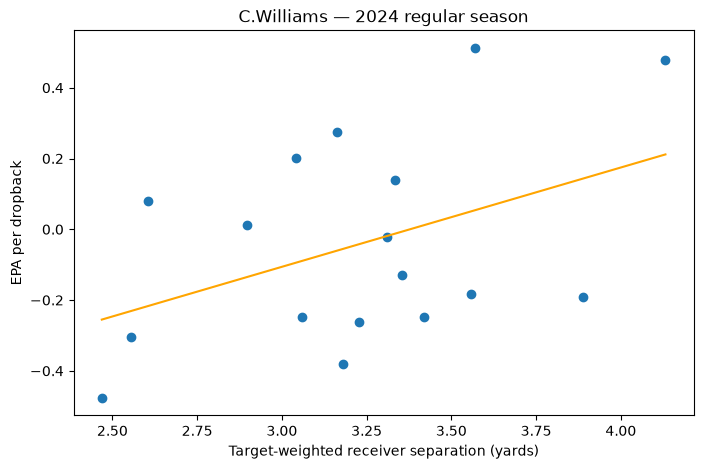

In [120]:
import matplotlib.pyplot as plt

top_qb = qb_separation_rankings.iloc[0]

games = analysis_games.loc[
    analysis_games["qb_id"] == top_qb["qb_id"]
]

slope, intercept = linear_regression(
    games["avg_separation"],
    games["epa_per_dropback"],
)

x = games["avg_separation"].sort_values()
predicted_epa = intercept + slope * x

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(games["avg_separation"], games["epa_per_dropback"])
ax.plot(x, predicted_epa, color="orange")

ax.set_xlabel("Target-weighted receiver separation (yards)")
ax.set_ylabel("EPA per dropback")
ax.set_title(f"{top_qb['qb_name']} — 2024 regular season")

plt.show()

## Examining the highest-ranked quarterback

Each point represents one qualifying game for the quarterback with the largest estimated slope. The horizontal axis shows target-weighted team receiver separation, and the vertical axis shows EPA per dropback. The orange line shows the fitted relationship, calculated as `intercept + slope * separation`.

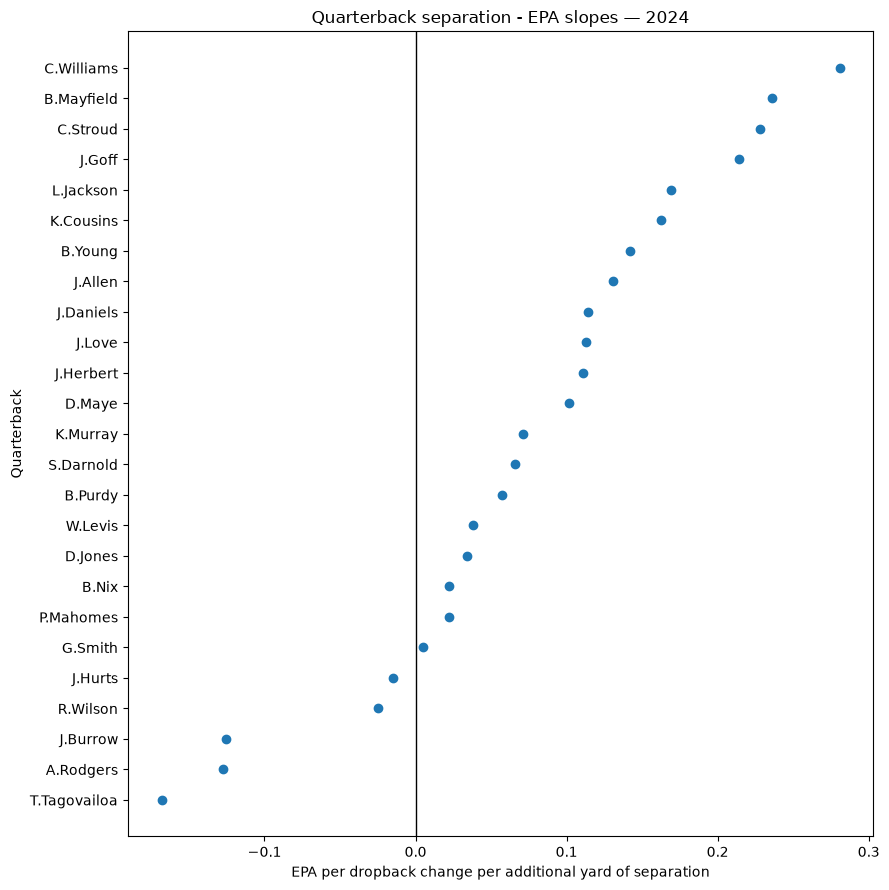

In [121]:
import matplotlib.pyplot as plt

rankings = qb_separation_rankings.sort_values("epa_change_per_yard")

fig, ax = plt.subplots(figsize=(9, 9))

ax.scatter(rankings["epa_change_per_yard"], rankings["qb_name"])
ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel("EPA per dropback change per additional yard of separation")
ax.set_ylabel("Quarterback")
ax.set_title("Quarterback separation - EPA slopes — 2024")

fig.tight_layout()
plt.show()

## Comparing quarterback slopes

This dot plot compares slopes for all 25 qualifying quarterbacks. Points to the right of zero indicate a positive association between separation and EPA per dropback. Points to the left indicate a negative association. The ranking reflects estimated slopes, with uncertainty still to be assessed.

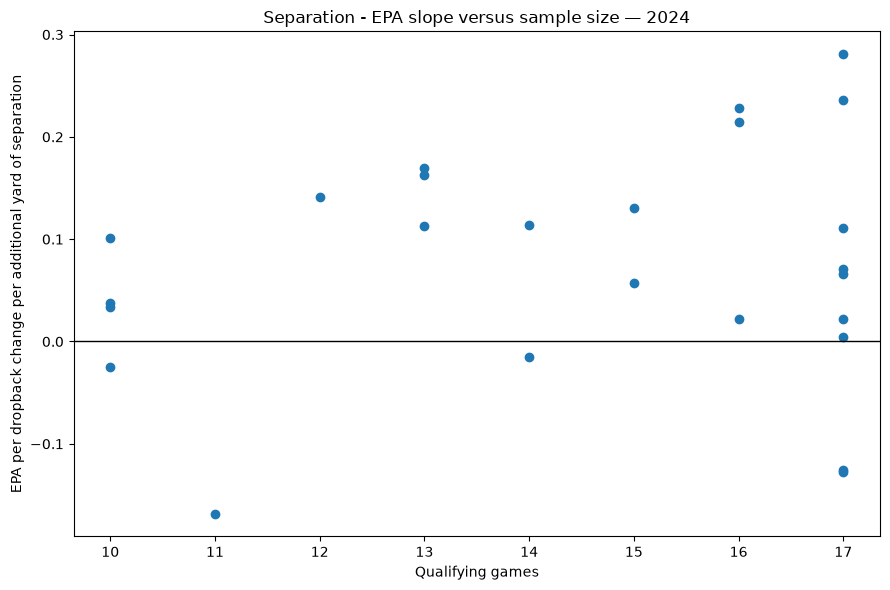

In [122]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    qb_separation_rankings["games"],
    qb_separation_rankings["epa_change_per_yard"],
)

ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Qualifying games")
ax.set_ylabel("EPA per dropback change per additional yard of separation")
ax.set_title("Separation - EPA slope versus sample size — 2024")

fig.tight_layout()
plt.show()

## Comparing slopes and sample sizes

Each point represents one quarterback. The horizontal axis shows the number of qualifying games, and the vertical axis shows the estimated separation–EPA slope. This plot shows how much game data supports each estimate. Game count alone does not establish precision.

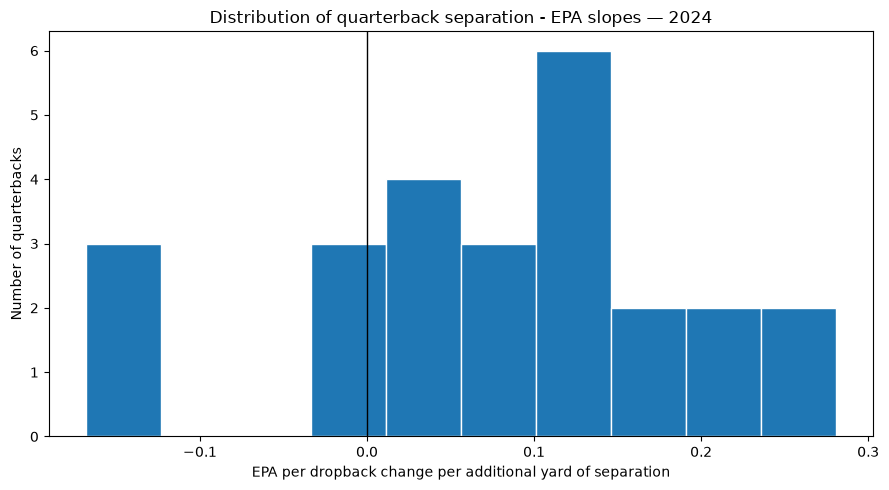

In [123]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    qb_separation_rankings["epa_change_per_yard"],
    bins=10,
    edgecolor="white",
)

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("EPA per dropback change per additional yard of separation")
ax.set_ylabel("Number of quarterbacks")
ax.set_title("Distribution of quarterback separation - EPA slopes — 2024")

fig.tight_layout()
plt.show()

## Viewing the distribution of slopes

This histogram groups the slope estimates into 10 intervals. Each bar shows how many quarterbacks fall within that interval, and the vertical line marks zero. It summarizes the spread of positive and negative associations across the qualifying quarterbacks.

# Takeaway

Caleb Williams, Baker Mayfield, and C.J. Stroud had the largest positive estimated relationships between receiver separation and EPA per dropback in the 2024 analysis. Across the 25 qualifying quarterbacks, 20 had positive slopes, suggesting that greater separation was generally associated with higher EPA per dropback.

These results describe associations within the available receiver data. Incomplete coverage and uncertainty in the estimated slopes limit how confidently quarterbacks can be ranked.